In [21]:
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
)

from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configuration
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 32
EPOCHS = 3
LEARNING_RATE = 2e-5

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {DEVICE}")

Device: cuda


In [22]:
import kagglehub
kagglehub.dataset_download("uciml/sms-spam-collection-dataset")

Using Colab cache for faster access to the 'sms-spam-collection-dataset' dataset.


'/kaggle/input/sms-spam-collection-dataset'

In [23]:
import pandas as pd

data = pd.read_csv(
    "/kaggle/input/sms-spam-collection-dataset/spam.csv",
    encoding="latin-1",
    usecols=["v1", "v2"]
)

data.columns = ["target", "text"]

# Remove missing or empty messages
data = data.dropna(subset=["target", "text"]).copy()
data["text"] = data["text"].astype(str).str.strip()
data = data[data["text"] != ""].copy()

# Encode labels: spam = 1, ham = 0
data["target"] = data["target"].map({
    "ham": 0,
    "spam": 1,
})

data = data.dropna(subset=["target"]).copy()
data["target"] = data["target"].astype(int)

print(f"Dataset shape: {data.shape}")
print("\nClass distribution:")
print(data["target"].value_counts())

data.head()

Dataset shape: (5572, 2)

Class distribution:
target
0    4825
1     747
Name: count, dtype: int64


,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    data["text"].to_numpy(),
    data["target"].to_numpy(),
    test_size=0.2,
    random_state=SEED,
    stratify=data["target"],
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts(normalize=True))

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts(normalize=True))

Training samples: 4457
Testing samples: 1115

Training class distribution:
0    0.865829
1    0.134171
Name: proportion, dtype: float64

Testing class distribution:
0    0.866368
1    0.133632
Name: proportion, dtype: float64


In [25]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(f"Tokenizer: {MODEL_NAME}")

Tokenizer: bert-base-uncased


In [26]:
class SMSDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = self.tokenizer(
            self.texts[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )

        item = {
            key: value.squeeze(0)
            for key, value in encoding.items()
        }

        item["labels"] = torch.tensor(
            self.labels[index],
            dtype=torch.long,
        )

        return item


train_dataset = SMSDataset(
    X_train, y_train, tokenizer, MAX_LENGTH
)

test_dataset = SMSDataset(
    X_test, y_test, tokenizer, MAX_LENGTH
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print(f"Training batches: {len(train_loader)}")
print(f"Testing batches: {len(test_loader)}")

Training batches: 140
Testing batches: 35


In [27]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "HAM",
        1: "SPAM",
    },
    label2id={
        "HAM": 0,
        "SPAM": 1,
    },
)

model.to(DEVICE)

print(f"Model: {MODEL_NAME}")
print(f"Number of labels: {model.config.num_labels}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: bert-base-uncased
Number of labels: 2


In [28]:
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01,
)

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps,
)

criterion = torch.nn.CrossEntropyLoss()

In [29]:
from tqdm.auto import tqdm

history = []

for epoch in range(EPOCHS):
    model.train()

    total_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}",
        leave=True,
    )

    for batch in progress_bar:
        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        optimizer.zero_grad()

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
        )

        loss = criterion(
            outputs.logits,
            batch["labels"],
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        # Display the current batch loss
        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = total_loss / len(train_loader)
    history.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} completed | "
        f"Average Loss: {epoch_loss:.4f}"
    )

Epoch 1/3:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 1/3 completed | Average Loss: 0.1731


Epoch 2/3:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 2/3 completed | Average Loss: 0.0218


Epoch 3/3:   0%|          | 0/140 [00:00<?, ?it/s]

Epoch 3/3 completed | Average Loss: 0.0100


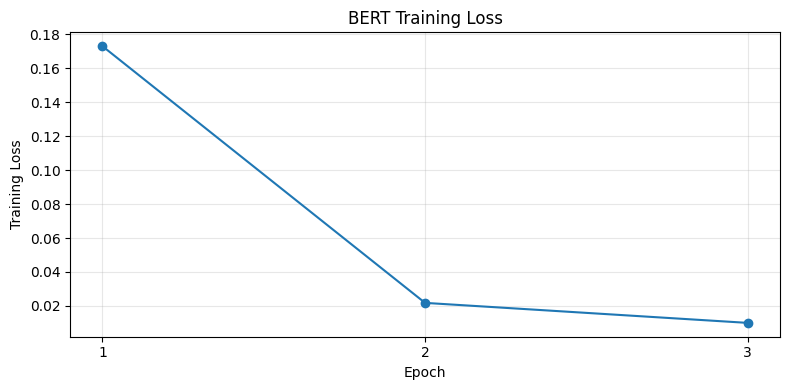

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, EPOCHS + 1),
    history,
    marker="o",
)

plt.title("BERT Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
model.eval()

all_predictions = []
all_probabilities = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
        )

        probabilities = torch.softmax(
            outputs.logits,
            dim=1,
        )

        predictions = probabilities.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

        all_labels.extend(
            batch["labels"].cpu().numpy()
        )

y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)
y_true = np.array(all_labels)

print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_true, y_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0,
    )
)

Accuracy:  0.9937
Precision: 0.9863
Recall:    0.9664
F1-score:  0.9763

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      1.00       966
        Spam       0.99      0.97      0.98       149

    accuracy                           0.99      1115
   macro avg       0.99      0.98      0.99      1115
weighted avg       0.99      0.99      0.99      1115



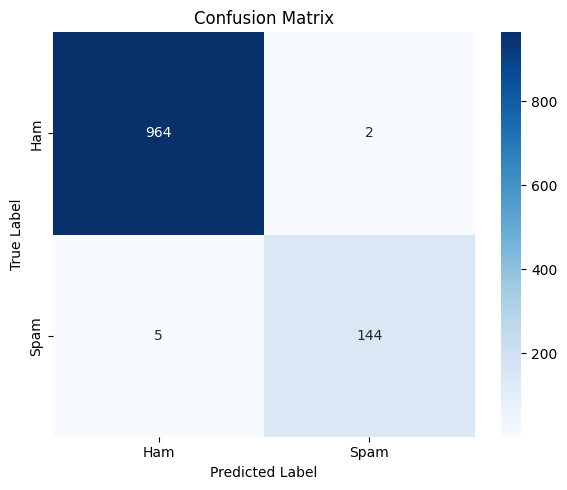

In [32]:
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1],
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [33]:
from pathlib import Path

MODEL_DIR = Path("artifacts/bert-spam-classifier")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print(f"Model saved to: {MODEL_DIR}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: artifacts/bert-spam-classifier


In [34]:
tokenizer = AutoTokenizer.from_pretrained(
    "artifacts/bert-spam-classifier"
)

model = AutoModelForSequenceClassification.from_pretrained(
    "artifacts/bert-spam-classifier"
)

model.to(DEVICE)
model.eval()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,